In [ ]:


import matplotlib.pyplot as plt
import numpy as np
import os
import scipy.io
plt.rcParams['figure.figsize'] = [8, 8]
plt.rcParams.update({'font.size': 18})

mat_contents = scipy.io.loadmat(os.path.join('..','DATA','allFaces.mat'))
faces = mat_contents['faces']
m = int(np.squeeze(mat_contents['m']))
n = int(np.squeeze(mat_contents['n']))
nfaces = np.ndarray.flatten(mat_contents['nfaces'])


# We use the first 36 people for training data
trainingFaces = faces[:,:np.sum(nfaces[:36])]
avgFace = np.mean(trainingFaces,axis=1) # size n*m by 1

print( "trainingFaces.shape[0]= " + str(trainingFaces.shape[0]) )
print( "trainingFaces.shape[1]= " + str(trainingFaces.shape[1]) )
print( "avgFace.shape = " + str(avgFace.shape) )
print( "np.tile(avgFace,(trainingFaces.shape[1],1))" + str(np.tile(avgFace,(trainingFaces.shape[1],1)).shape) )

# Compute eigenfaces on mean-subtracted training data
X = trainingFaces - np.tile(avgFace,(trainingFaces.shape[1],1)).T
U, S, VT = np.linalg.svd(X,full_matrices=0)

print( "U.shape = " + str(U.shape) )

fig1 = plt.figure()
ax1 = fig1.add_subplot(121)
img_avg = ax1.imshow(np.reshape(avgFace,(m,n)).T)
img_avg.set_cmap('gray')
plt.axis('off')


ax2 = fig1.add_subplot(122)
img_u1 = ax2.imshow(np.reshape(U[:,1],(m,n)).T)
img_u1.set_cmap('gray')
plt.axis('off')

plt.show()


allUs = np.zeros((n*6,m*6))
for j in range(6):
    for k in range(6):
        allUs[j*n : (j+1)*n, k*m : (k+1)*m] = np.reshape(U[:,j*6+k],(m,n)).T

plt.axis('off')
plt.imshow(allUs)



trainingFaces.shape[0]= 32256
trainingFaces.shape[1]= 2282
avgFace.shape = (32256,)
np.tile(avgFace,(trainingFaces.shape[1],1))(2282, 32256)


In the below code:


The RAM spikes because the original line builds a huge dense matrix with $U_r U_r^T$.

- $U_r$ has shape $(mn) \times r$. For faces, $mn$ is the number of pixels (e.g., $112 \times 92 = 10304$), so $U_r U_r^T$ becomes a $(mn) \times (mn)$ matrix.
- That’s roughly $10304^2 \approx 1.06 \times 10^8$ floats. At 8 bytes per float64, that’s about 0.85 GB just for that one matrix, plus overhead and temporary buffers during the matmul.
- NumPy will allocate additional temporary arrays during the chained multiply, so peak memory can easily exceed a few GB and lock up VS Code.

The fix avoids forming $U_r U_r^T$ by doing $U_r (U_r^T \, \text{testFaceMS})$, which only uses vectors/matrices of size $(mn)\times r$ and $r\times 1$, so memory stays small.

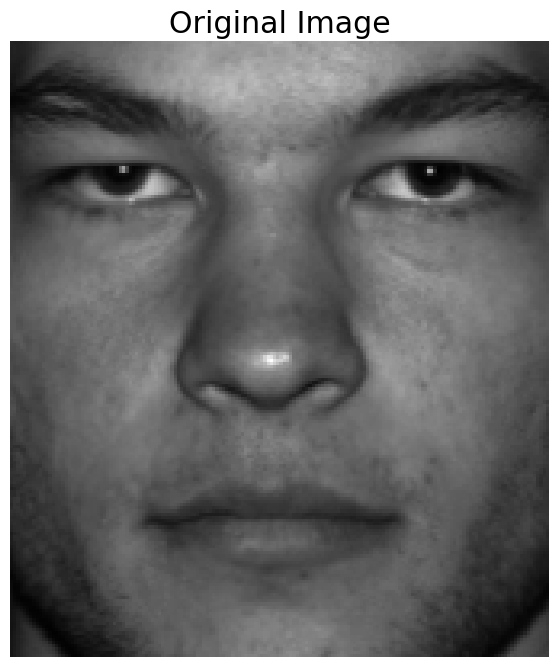

coeffs.shape = (25,)
approxI.shape = (32256,)


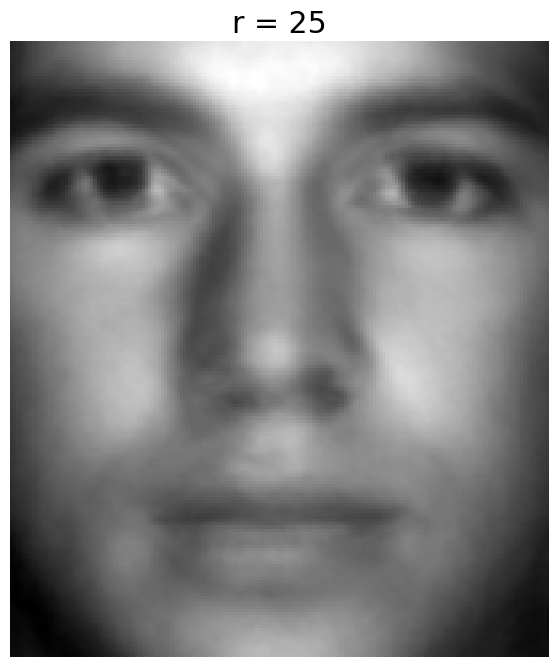

coeffs.shape = (50,)
approxI.shape = (32256,)


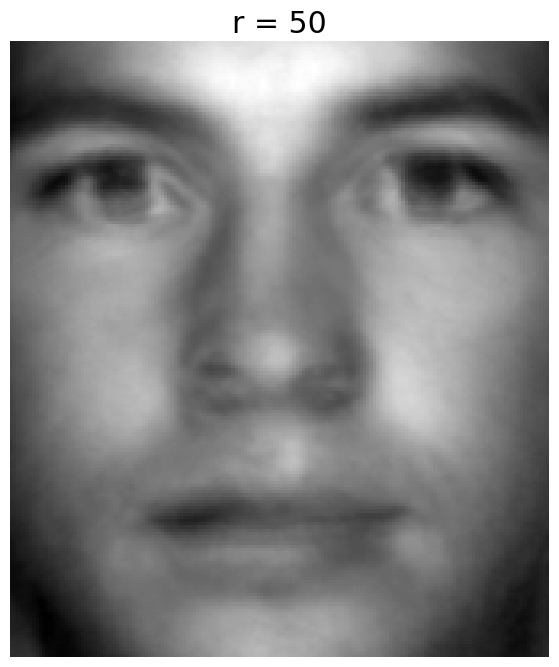

coeffs.shape = (100,)
approxI.shape = (32256,)


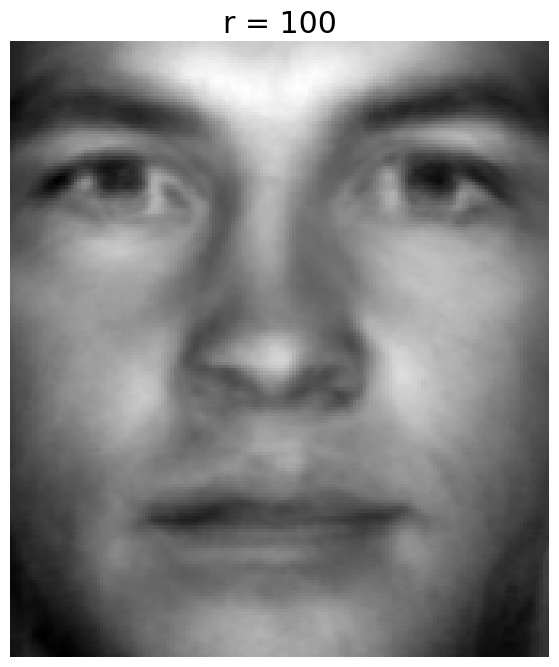

coeffs.shape = (200,)
approxI.shape = (32256,)


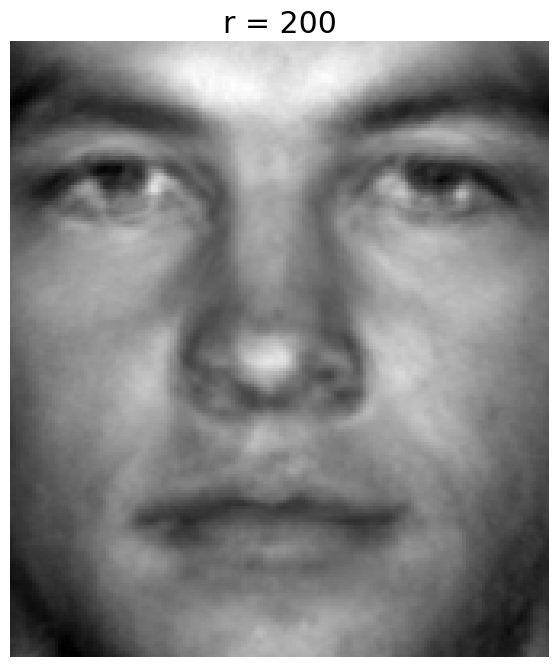

coeffs.shape = (400,)
approxI.shape = (32256,)


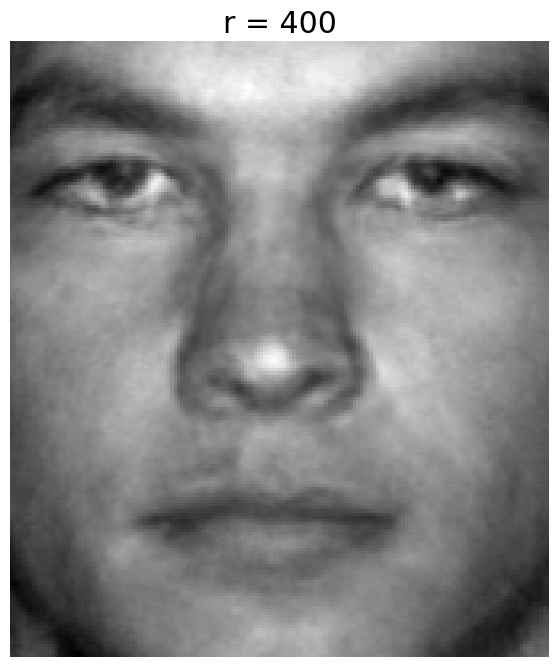

coeffs.shape = (800,)
approxI.shape = (32256,)


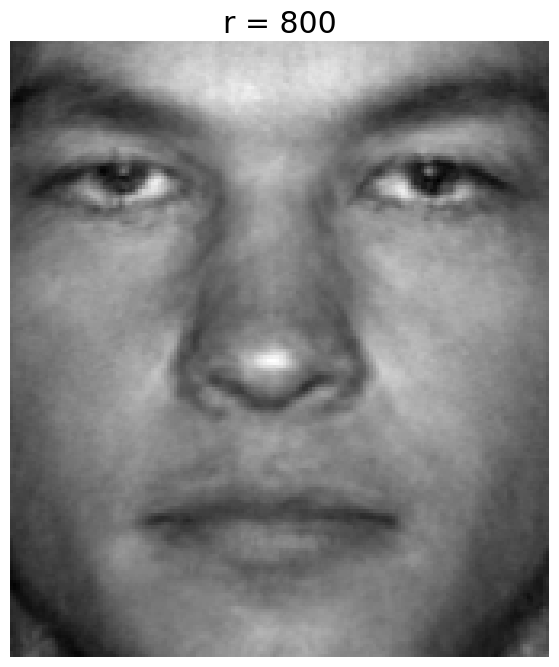

coeffs.shape = (1200,)
approxI.shape = (32256,)


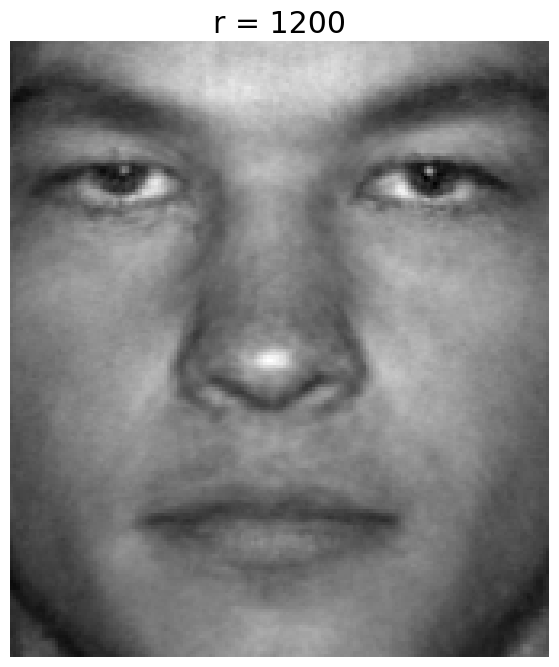

coeffs.shape = (1600,)
approxI.shape = (32256,)


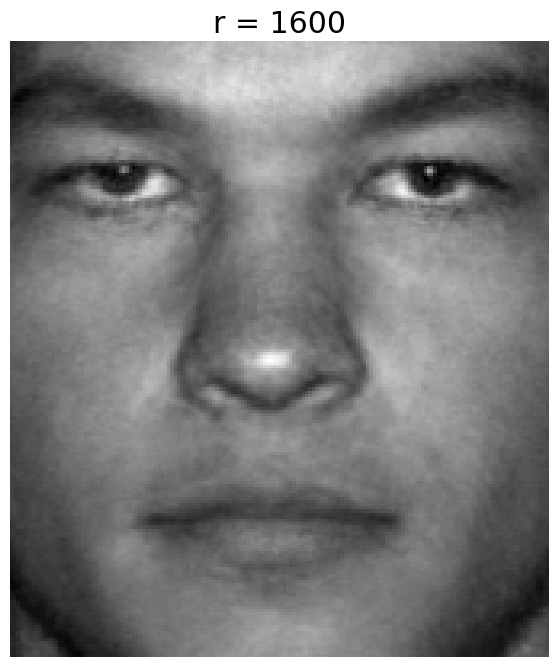

In [ ]:

## Now show eigenface reconstruction of image that was omitted from test set

testFace = faces[:,np.sum(nfaces[:36])] # First face of person 37
plt.imshow(np.reshape(testFace,(m,n)).T)
plt.set_cmap('gray')
plt.title('Original Image')
plt.axis('off')
plt.show()

testFaceMS = testFace - avgFace
r_list = [25, 50, 100, 200, 400, 800, 1200, 1600]

for r in r_list:
    # Original (kept for reference):
    # reconFace = avgFace + U[:,:r]  @ U[:,:r].T @ testFaceMS
    U_r = U[:, :r]
    # Project onto the r-dimensional subspace without forming the full U_r @ U_r.T

    
    coeffs = U_r.T @ testFaceMS
    print( "coeffs.shape = " + str(coeffs.shape) )
    approxI = U_r @ coeffs
    print( "approxI.shape = " + str(approxI.shape) )
    reconFace = avgFace + approxI
    img = plt.imshow(np.reshape(reconFace,(m,n)).T)
    img.set_cmap('gray')
    plt.title('r = ' + str(r))
    plt.axis('off')
    plt.show()



P1.shape = (32256, 62)
P2.shape = (32256, 64)
(2, 62)
(2, 64)


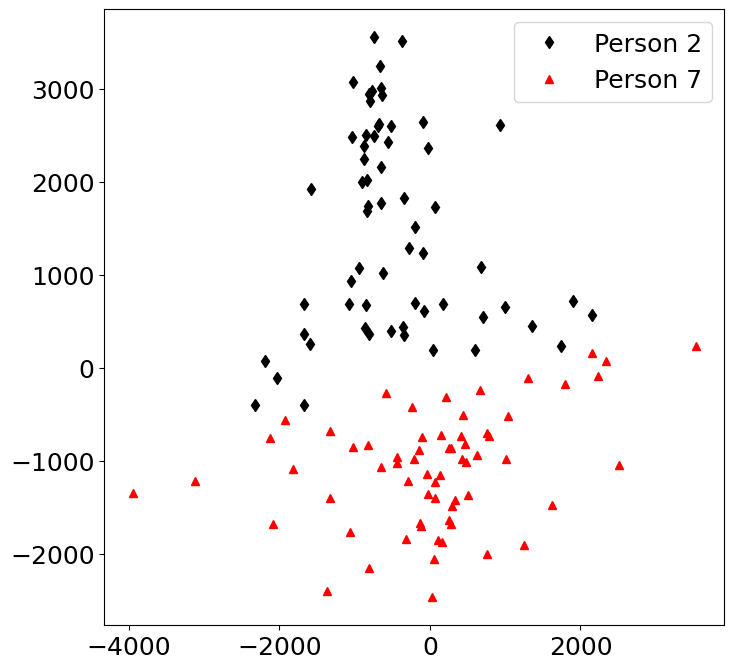

In [ ]:

## Project person 2 and 7 onto PC5 and PC6

P1num = 2 # Person number 2
P2num = 7 # Person number 7

P1 = faces[:,np.sum(nfaces[:(P1num-1)]):np.sum(nfaces[:P1num])]
P2 = faces[:,np.sum(nfaces[:(P2num-1)]):np.sum(nfaces[:P2num])]

P1 = P1 - np.tile(avgFace,(P1.shape[1],1)).T
P2 = P2 - np.tile(avgFace,(P2.shape[1],1)).T


print( "P1.shape = " + str(P1.shape) )
print( "P2.shape = " + str(P2.shape) )
PCAmodes = [5, 6] # Project onto PCA modes 5 and 6
PCACoordsP1 = U[:,PCAmodes-np.ones_like(PCAmodes)].T @ P1
PCACoordsP2 = U[:,PCAmodes-np.ones_like(PCAmodes)].T @ P2

print( PCACoordsP1.shape )
print( PCACoordsP2.shape )  
plt.plot(PCACoordsP1[0,:],PCACoordsP1[1,:],'d',color='k',label='Person 2')
plt.plot(PCACoordsP2[0,:],PCACoordsP2[1,:],'^',color='r',label='Person 7')

plt.legend()
plt.show()



## Comparing Family Faces using Eigenfaces

We now apply the same eigenface framework to 4 family photos (Lakshmi, Sreeram, Aardra, Vrinda).

Each face is:
1. Loaded, converted to grayscale, and resized to a common resolution.
2. Flattened into a pixel vector and stacked into a data matrix $F$.
3. Mean-subtracted: $X = F - \bar{f}\mathbf{1}^T$.
4. Decomposed via SVD: $X = U\Sigma V^T$ — columns of $U$ are the eigenfaces.
5. Projected onto eigenface coordinates: $\text{coords}_i = U^T x_i$.
6. Compared by Euclidean distance in eigenface space: $d(i,j) = \|\text{coords}_i - \text{coords}_j\|_2$.

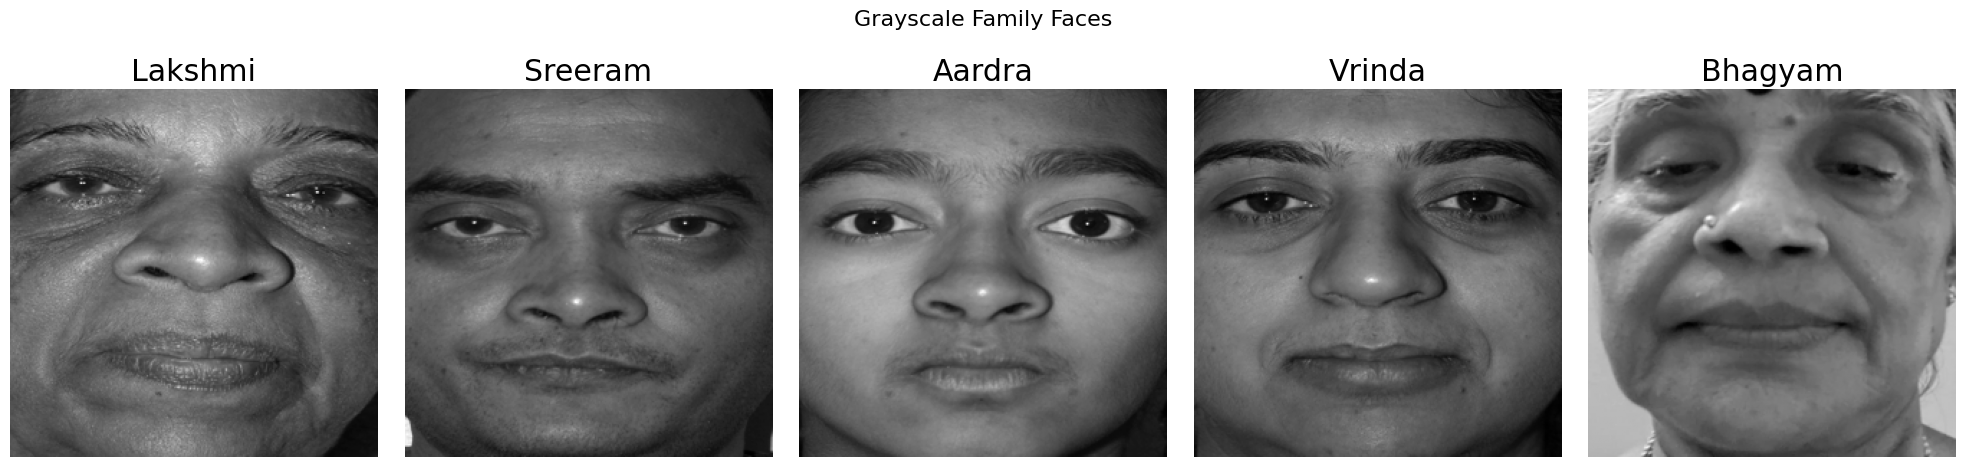

Training image size: m=168 (width), n=192 (height), pixels=32256
Family face matrix shape: (32256, 5)
Training eigenfaces U shape: (32256, 2282)


In [ ]:
from PIL import Image

data_dir = os.path.join('..', 'DATA')
image_files = ['lakshmi.jpeg', 'sreeram.jpeg', 'aardra.jpeg', 'vrinda.jpeg', 'bhagyam.jpeg']
fam_names  = ['Lakshmi', 'Sreeram', 'Aardra', 'Vrinda', 'Bhagyam']

# --- Display family faces as grayscale at a readable size ---
DISPLAY_SIZE = (256, 256)
fig, axes = plt.subplots(1, 5, figsize=(20, 5))
for ax, fname, name in zip(axes, image_files, fam_names):
    img = Image.open(os.path.join(data_dir, fname)).convert('L').resize(DISPLAY_SIZE)
    ax.imshow(np.array(img), cmap='gray')
    ax.set_title(name)
    ax.axis('off')
plt.suptitle('Grayscale Family Faces', fontsize=16)
plt.tight_layout()
plt.show()

# --- Resize each face to match the training data dimensions (m x n) ---
# PIL resize takes (width, height). The training images have width=m, height=n.
fam_vectors = []
for fname in image_files:
    img = Image.open(os.path.join(data_dir, fname)).convert('L').resize((m, n))
    fam_vectors.append(np.array(img, dtype=np.float64).flatten())

F_fam = np.column_stack(fam_vectors)   # shape (m*n, 5)
print(f"Training image size: m={m} (width), n={n} (height), pixels={m*n}")
print(f"Family face matrix shape: {F_fam.shape}")
print(f"Training eigenfaces U shape: {U.shape}")


Projecting onto top 50 eigenfaces
Eigenface coordinate norms (energy in face space):
  Lakshmi: norm = 4532.5
  Sreeram: norm = 3439.9
  Aardra: norm = 4245.5
  Vrinda: norm = 3879.5
  Bhagyam: norm = 7118.3


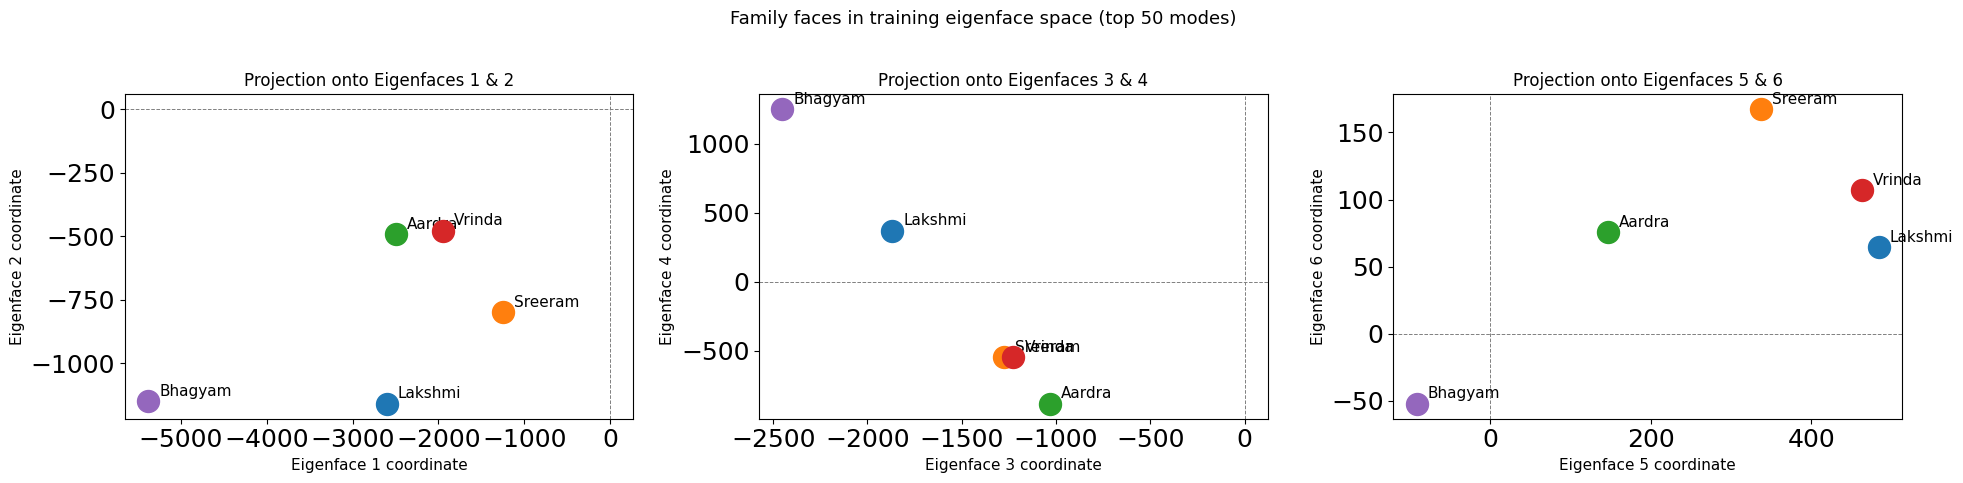


Pairwise distances in eigenface space (top 50 modes) — smaller = more similar:
               Lakshmi     Sreeram      Aardra      Vrinda     Bhagyam
Lakshmi            0.0      1929.0      2108.2      1587.3      4216.4
Sreeram         1929.0         0.0      1900.2      1238.8      5590.3
Aardra          2108.2      1900.2         0.0      1232.4      4702.6
Vrinda          1587.3      1238.8      1232.4         0.0      5119.8
Bhagyam         4216.4      5590.3      4702.6      5119.8         0.0


In [ ]:
# --- Project family faces onto training eigenfaces ---
# Mean-subtract using the training average face
F_fam_ms = F_fam - avgFace[:, np.newaxis]

# Use top r eigenfaces for comparison
r = 50
U_r = U[:, :r]
coords = U_r.T @ F_fam_ms   # shape (r, 4)

print(f"Projecting onto top {r} eigenfaces")
print("Eigenface coordinate norms (energy in face space):")
for i, name in enumerate(fam_names):
    print(f"  {name}: norm = {np.linalg.norm(coords[:, i]):.1f}")

colors = ['tab:blue', 'tab:orange', 'tab:green', 'tab:red', 'tab:purple']

# --- 2D scatter plots: Eigenfaces 1&2, 3&4, 5&6 ---
fig, axes = plt.subplots(1, 3, figsize=(20, 5))

plot_pairs = [
    (0, 1, 'Eigenfaces 1 & 2'),
    (2, 3, 'Eigenfaces 3 & 4'),
    (4, 5, 'Eigenfaces 5 & 6'),
]

for ax, (xi, yi, title) in zip(axes, plot_pairs):
    for i, (name, color) in enumerate(zip(fam_names, colors)):
        ax.scatter(coords[xi, i], coords[yi, i], s=250, color=color, zorder=3)
        ax.annotate(name, (coords[xi, i], coords[yi, i]),
                    textcoords='offset points', xytext=(8, 4), fontsize=11)
    ax.axhline(0, color='gray', lw=0.7, ls='--')
    ax.axvline(0, color='gray', lw=0.7, ls='--')
    ax.set_xlabel(f'Eigenface {xi+1} coordinate', fontsize=11)
    ax.set_ylabel(f'Eigenface {yi+1} coordinate', fontsize=11)
    ax.set_title(f'Projection onto {title}', fontsize=12)

plt.suptitle(f'Family faces in training eigenface space (top {r} modes)', fontsize=13)
plt.tight_layout()
plt.show()

# --- Pairwise Euclidean distance table ---
print(f"\nPairwise distances in eigenface space (top {r} modes) — smaller = more similar:")
print(f"{'':10s}", end='')
for name in fam_names:
    print(f"{name:>12s}", end='')
print()
for i, n1 in enumerate(fam_names):
    print(f"{n1:10s}", end='')
    for j, n2 in enumerate(fam_names):
        dist = np.linalg.norm(coords[:, i] - coords[:, j])
        print(f"{dist:12.1f}", end='')
    print()
